# Cross-Validating the Delay-Discounting Model

## Question

Can participant-level delay-discounting parameters estimated from a subset
of decisions generalize to unseen intertemporal choices?

This notebook evaluates the hyperbolic choice model using 5-fold
cross-validation.

For each participant:

1. Divide their trials into five folds.
2. Fit k and β using four folds.
3. Predict choices in the held-out fold.
4. Repeat until every trial has been held out once.
5. Compare the model's held-out performance with a majority-choice baseline.

Unlike the in-sample analysis in Notebook 5, parameter estimation and
evaluation are performed on separate observations.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

In [2]:
file_path = Path("../data/raw/all_data.csv")

selected_paper = "Becker_2023_Exp1"

usecols = [
    "paper",
    "subj_ident",
    "trial_idx",
    "ss_value",
    "ss_time",
    "ll_value",
    "ll_time",
    "choice",
    "subj_excl",
    "trial_excl"
]

study_parts = []

for chunk in pd.read_csv(
    file_path,
    usecols=usecols,
    chunksize=100_000
):
    match = chunk[
        chunk["paper"] == selected_paper
    ]

    if not match.empty:
        study_parts.append(match)

study_df = pd.concat(
    study_parts,
    ignore_index=True
)

clean_df = study_df[
    (~study_df["subj_excl"]) &
    (~study_df["trial_excl"])
].copy()

print("Trials:", len(clean_df))
print(
    "Participants:",
    clean_df["subj_ident"].nunique()
)

Trials: 9898
Participants: 159


## Model Fitting

Within each training fold, participant-specific values of `k` and `β` are
estimated by maximizing the likelihood of the observed training choices.

The same expanded parameter ranges used in the final real-data analysis are
used throughout cross-validation.

In [3]:
def real_log_likelihood_vectorized(
    k,
    beta,
    participant_df
):
    ss_value = participant_df["ss_value"].to_numpy()
    ss_time = participant_df["ss_time"].to_numpy()

    ll_value = participant_df["ll_value"].to_numpy()
    ll_time = participant_df["ll_time"].to_numpy()

    choices = participant_df["choice"].to_numpy()

    ss_subjective = ss_value / (
        1 + k * ss_time
    )

    ll_subjective = ll_value / (
        1 + k * ll_time
    )

    value_difference = (
        ll_subjective - ss_subjective
    )

    p_ll = 1 / (
        1 + np.exp(
            -beta * value_difference
        )
    )

    p_ll = np.clip(
        p_ll,
        1e-10,
        1 - 1e-10
    )

    choice_probabilities = np.where(
        choices == 1,
        p_ll,
        1 - p_ll
    )

    return np.log(
        choice_probabilities
    ).sum()

def fit_participant(
    participant_df,
    candidate_ks,
    candidate_betas
):
    best_ll = -np.inf
    best_k = None
    best_beta = None

    for beta in candidate_betas:
        for k in candidate_ks:

            ll = real_log_likelihood_vectorized(
                k,
                beta,
                participant_df
            )

            if ll > best_ll:
                best_ll = ll
                best_k = k
                best_beta = beta

    return best_k, best_beta, best_ll

candidate_ks = np.logspace(
    np.log10(0.000001),
    np.log10(1),
    200
)

candidate_betas = np.logspace(
    np.log10(0.001),
    np.log10(10),
    160
)

## Held-Out Prediction

After fitting the model on the training folds, the estimated parameters are
used to generate larger-later choice probabilities for the held-out trials.

Performance is evaluated using both classification accuracy and binary log loss.

In [4]:
def predict_ll_probability(df, k, beta):
    ss_value = df["ss_value"].to_numpy()
    ss_time = df["ss_time"].to_numpy()

    ll_value = df["ll_value"].to_numpy()
    ll_time = df["ll_time"].to_numpy()

    ss_subjective = ss_value / (
        1 + k * ss_time
    )

    ll_subjective = ll_value / (
        1 + k * ll_time
    )

    value_difference = (
        ll_subjective - ss_subjective
    )

    p_ll = 1 / (
        1 + np.exp(
            -beta * value_difference
        )
    )

    return p_ll

In [5]:
def binary_log_loss(actual, probabilities):
    probabilities = np.clip(
        probabilities,
        1e-10,
        1 - 1e-10
    )

    return -np.mean(
        actual * np.log(probabilities)
        + (1 - actual) * np.log(1 - probabilities)
    )

## Five-Fold Cross-Validation

Each participant's trials are randomly divided into five folds.

For every fold:

1. `k` and `β` are estimated from the other four folds.
2. The fitted model predicts choices in the held-out fold.
3. A training-set majority-choice baseline is evaluated on the same held-out
   trials.
4. Accuracy and log loss are recorded.

Each trial therefore contributes to evaluation exactly once.

In [6]:
def cross_validate_participant(
    participant_df,
    candidate_ks,
    candidate_betas,
    n_folds=5,
    seed=42
):
    participant_df = participant_df.reset_index(drop=True)

    rng = np.random.default_rng(seed)

    indices = np.arange(len(participant_df))
    rng.shuffle(indices)

    folds = np.array_split(
        indices,
        n_folds
    )

    fold_results = []

    for fold_index in range(n_folds):

        test_indices = folds[fold_index]

        train_indices = np.concatenate([
            folds[i]
            for i in range(n_folds)
            if i != fold_index
        ])

        train_df = participant_df.iloc[
            train_indices
        ].copy()

        test_df = participant_df.iloc[
            test_indices
        ].copy()

        estimated_k, estimated_beta, _ = fit_participant(
            train_df,
            candidate_ks,
            candidate_betas
        )

        p_ll = predict_ll_probability(
            test_df,
            estimated_k,
            estimated_beta
        )

        actual = test_df[
            "choice"
        ].to_numpy()

        predicted = (
            p_ll >= 0.5
        ).astype(int)

        model_accuracy = (
            predicted == actual
        ).mean()

        model_log_loss = binary_log_loss(
            actual,
            p_ll
        )

        training_ll_rate = (
            train_df["choice"].mean()
        )

        baseline_choice = (
            1
            if training_ll_rate >= 0.5
            else 0
        )

        baseline_accuracy = (
            actual == baseline_choice
        ).mean()

        baseline_probs = np.full(
            len(test_df),
            training_ll_rate
        )

        baseline_log_loss = binary_log_loss(
            actual,
            baseline_probs
        )

        fold_results.append({
            "n_test": len(test_df),
            "estimated_k": estimated_k,
            "estimated_beta": estimated_beta,
            "model_accuracy": model_accuracy,
            "baseline_accuracy": baseline_accuracy,
            "model_log_loss": model_log_loss,
            "baseline_log_loss": baseline_log_loss
        })

    return pd.DataFrame(fold_results)

## Cross-Validate All Participants

The five-fold procedure is applied independently to all 159 participants.
Fold-level scores are combined using test-fold size as the weight so that
participants with uneven fold sizes receive correctly weighted performance
estimates.

In [7]:
participant_results = []

participant_ids = clean_df["subj_ident"].unique()

for i, participant_id in enumerate(participant_ids):

    participant_df = clean_df[
        clean_df["subj_ident"] == participant_id
    ].copy()

    fold_df = cross_validate_participant(
        participant_df,
        candidate_ks,
        candidate_betas
    )

    cv_model_accuracy = np.average(
        fold_df["model_accuracy"],
        weights=fold_df["n_test"]
    )

    cv_baseline_accuracy = np.average(
        fold_df["baseline_accuracy"],
        weights=fold_df["n_test"]
    )

    cv_model_log_loss = np.average(
        fold_df["model_log_loss"],
        weights=fold_df["n_test"]
    )

    cv_baseline_log_loss = np.average(
        fold_df["baseline_log_loss"],
        weights=fold_df["n_test"]
    )

    participant_results.append({
        "subj_ident": participant_id,
        "n_trials": len(participant_df),

        "cv_model_accuracy": cv_model_accuracy,
        "cv_baseline_accuracy": cv_baseline_accuracy,

        "accuracy_gain": (
            cv_model_accuracy
            - cv_baseline_accuracy
        ),

        "cv_model_log_loss": cv_model_log_loss,
        "cv_baseline_log_loss": cv_baseline_log_loss,

        # Positive = model is better
        "log_loss_gain": (
            cv_baseline_log_loss
            - cv_model_log_loss
        )
    })

    print(
        f"{i + 1}/{len(participant_ids)} "
        f"{participant_id}"
    )

cv_results_df = pd.DataFrame(
    participant_results
)

1/159 007_0001
2/159 007_0002
3/159 007_0003
4/159 007_0004
5/159 007_0005
6/159 007_0006
7/159 007_0007
8/159 007_0008
9/159 007_0009
10/159 007_0010
11/159 007_0012
12/159 007_0013
13/159 007_0014
14/159 007_0015
15/159 007_0017
16/159 007_0020
17/159 007_0021
18/159 007_0022
19/159 007_0023
20/159 007_0024
21/159 007_0026
22/159 007_0027
23/159 007_0028
24/159 007_0029
25/159 007_0030
26/159 007_0031
27/159 007_0032
28/159 007_0033
29/159 007_0035
30/159 007_0036
31/159 007_0038
32/159 007_0039
33/159 007_0040
34/159 007_0041
35/159 007_0042
36/159 007_0043
37/159 007_0044
38/159 007_0045
39/159 007_0046
40/159 007_0047
41/159 007_0048
42/159 007_0049
43/159 007_0050
44/159 007_0051
45/159 007_0052
46/159 007_0053
47/159 007_0054
48/159 007_0055
49/159 007_0056
50/159 007_0057
51/159 007_0058
52/159 007_0059
53/159 007_0060
54/159 007_0061
55/159 007_0062
56/159 007_0063
57/159 007_0064
58/159 007_0065
59/159 007_0066
60/159 007_0067
61/159 007_0068
62/159 007_0069
63/159 007_0070
6

In [8]:
cv_results_df[
    [
        "cv_model_accuracy",
        "cv_baseline_accuracy",
        "accuracy_gain",
        "cv_model_log_loss",
        "cv_baseline_log_loss",
        "log_loss_gain"
    ]
].describe()

,cv_model_accuracy,cv_baseline_accuracy,accuracy_gain,cv_model_log_loss,cv_baseline_log_loss,log_loss_gain
count,159.000000,159.000000,159.000000,159.000000,1.590000e+02,159.000000
mean,0.767769,0.646965,0.120804,0.510894,6.375748e-01,0.126681
std,0.109083,0.133081,0.115761,0.172240,9.165716e-02,0.160508
min,0.315789,0.309091,-0.133333,0.018127,1.000000e-10,-0.381808
25%,0.706691,0.589328,0.044643,0.415680,6.178434e-01,0.018645
50%,0.777778,0.653846,0.113208,0.516800,6.609725e-01,0.135445
75%,0.836972,0.715251,0.170593,0.633686,6.907873e-01,0.240576
max,0.979592,1.000000,0.511628,1.081118,7.744497e-01,0.578699


In [9]:
print(
    "Model beats baseline in accuracy:",
    (cv_results_df["accuracy_gain"] > 0).sum()
)

print(
    "Model ties baseline in accuracy:",
    (cv_results_df["accuracy_gain"] == 0).sum()
)

print(
    "Model below baseline in accuracy:",
    (cv_results_df["accuracy_gain"] < 0).sum()
)

print()

print(
    "Model beats baseline in log loss:",
    (cv_results_df["log_loss_gain"] > 0).sum()
)

print(
    "Model below baseline in log loss:",
    (cv_results_df["log_loss_gain"] < 0).sum()
)

Model beats baseline in accuracy: 131
Model ties baseline in accuracy: 7
Model below baseline in accuracy: 21

Model beats baseline in log loss: 121
Model below baseline in log loss: 38


## Out-of-Sample Performance

Positive values indicate that the fitted model outperformed the
participant-specific baseline on held-out trials.

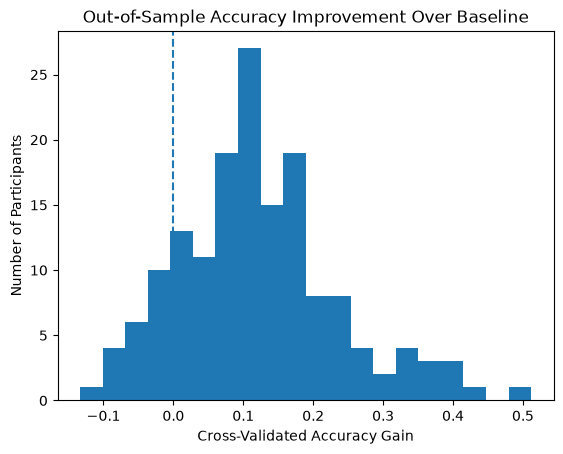

In [10]:
plt.hist(
    cv_results_df["accuracy_gain"],
    bins=20
)

plt.axvline(0, linestyle="--")

plt.xlabel("Cross-Validated Accuracy Gain")
plt.ylabel("Number of Participants")
plt.title("Out-of-Sample Accuracy Improvement Over Baseline")

plt.show()

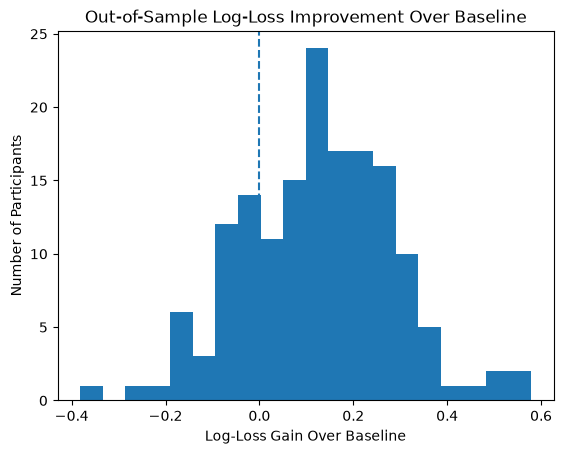

In [11]:
plt.hist(
    cv_results_df["log_loss_gain"],
    bins=20
)

plt.axvline(0, linestyle="--")

plt.xlabel("Log-Loss Gain Over Baseline")
plt.ylabel("Number of Participants")
plt.title("Out-of-Sample Log-Loss Improvement Over Baseline")

plt.show()

## Bootstrap Confidence Intervals

To quantify uncertainty in average model improvement, participants are
resampled with replacement 10,000 times.

The 2.5th and 97.5th percentiles of the bootstrap distribution provide a
participant-level 95% confidence interval for the mean improvement.

In [12]:
rng = np.random.default_rng(42)

accuracy_bootstrap = []
log_loss_bootstrap = []

for _ in range(10000):

    sample = cv_results_df.sample(
        n=len(cv_results_df),
        replace=True,
        random_state=rng.integers(0, 1_000_000)
    )

    accuracy_bootstrap.append(
        sample["accuracy_gain"].mean()
    )

    log_loss_bootstrap.append(
        sample["log_loss_gain"].mean()
    )

accuracy_ci = np.percentile(
    accuracy_bootstrap,
    [2.5, 97.5]
)

log_loss_ci = np.percentile(
    log_loss_bootstrap,
    [2.5, 97.5]
)

print("Mean accuracy gain:", cv_results_df["accuracy_gain"].mean())
print("95% bootstrap CI:", accuracy_ci)

print()

print("Mean log-loss gain:", cv_results_df["log_loss_gain"].mean())
print("95% bootstrap CI:", log_loss_ci)

Mean accuracy gain: 0.12080355011960262
95% bootstrap CI: [0.10319085 0.13887648]

Mean log-loss gain: 0.12668091194896217
95% bootstrap CI: [0.10181788 0.1514448 ]


## Conclusion

Five-fold cross-validation showed that the fitted hyperbolic
delay-discounting model generalized to choices that were not used for
parameter estimation.

Across 159 participants, the model achieved approximately 76.8% held-out
classification accuracy, compared with approximately 64.7% for a
participant-specific majority-choice baseline. This corresponds to an
average accuracy improvement of 12.1 percentage points.

A participant-level bootstrap estimated a 95% confidence interval for the
mean accuracy improvement of approximately 10.3 to 13.9 percentage points.

The model also improved probabilistic predictions. Mean log-loss
improvement over the baseline was approximately 0.127, with a 95%
bootstrap confidence interval of approximately 0.102 to 0.151.

The model outperformed the baseline in accuracy for 131 of 159
participants and in log loss for 121 of 159 participants.

These results suggest that participant-specific hyperbolic discounting
parameters capture systematic decision-making behavior that generalizes
beyond the observations used to estimate the parameters. However, this
analysis evaluates generalization to held-out trials from the same task
and study, rather than to new participants, studies, or entirely novel
choice environments.

In [13]:
output_path = Path(
    "../data/processed/cross_validation_results.csv"
)

output_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

cv_results_df.to_csv(
    output_path,
    index=False
)